In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator

In [10]:
def segal(filepath):
    df = pd.read_csv(filepath, quotechar="'")
    x = df.iloc[:, 0]
    y_raw = df.iloc[:, 1]
    
    #Linear baseline correction
    coeffs = np.polyfit([x.iloc[1], x.iloc[-1]], [y_raw.iloc[1], y_raw.iloc[-1]], 1)
    baseline = np.polyval(coeffs, x)
    y = y_raw - baseline

    #Find intensities for amorphous and crystalline fraction
    mask = (x >= 17) & (x <= 19)
    y_min = y[mask].min()
    idx = y[mask].idxmin()
    x_at_min = x[idx]
    print('I_amorphous = ' + str(y_min) + ', at x = ' + str(x_at_min))

    mask = (x >= 22) & (x <= 23)
    y_max = y[mask].max()
    idx = y[mask].idxmax()
    x_at_max = x[idx]
    print('I_crystalline = ' + str(y_max) + ', at x = ' + str(x_at_max))

    # calculate CI
    CI = 100*(y_max-y_min)/y_max
    print('CI = ' + str(CI))

    #Plot data 
    fig, axs = plt.subplots(2, 1, sharey=True, figsize=(3,5))
    axs[0].plot(x, y_raw, 'k')
    axs[0].plot(x, baseline, 'b', linewidth = 0.8)
    axs[1].plot(x, y, 'k')
    axs[1].vlines(x_at_min, 0, 50000, colors = 'r', linewidth = 0.8)
    axs[1].vlines(x_at_max, 0, 50000, colors = 'k', linewidth = 0.8)    

    axs[0].xaxis.set_major_locator(MultipleLocator(10))
    axs[1].xaxis.set_major_locator(MultipleLocator(10))
    axs[0].set_xlabel('2θ')
    axs[0].set_ylabel('Intensity (arb. u.')
    axs[1].set_ylabel('Intensity (arb. u.)')
    axs[0].set_title('Baseline correction')
    axs[1].set_title('Segal method')

I_amorphous = 3238.781005497178, at x = 18.2408
I_crystalline = 41659.163274791164, at x = 22.3385
CI = 92.22552554852432


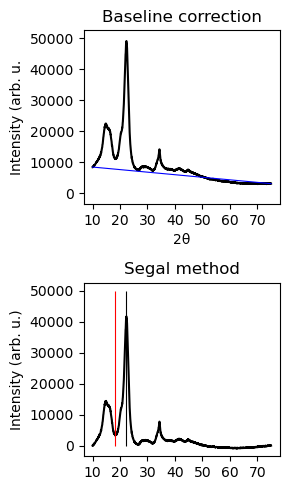

In [12]:
filepath = "Avicel_Segal.txt"
segal(filepath)
plt.tight_layout()
plt.savefig('Avicel_Segal.svg', bbox_inches = 'tight')

I_amorphous = 6035.076769654103, at x = 17.9706
I_crystalline = 32768.81377926339, at x = 22.1584
CI = 81.582864700848


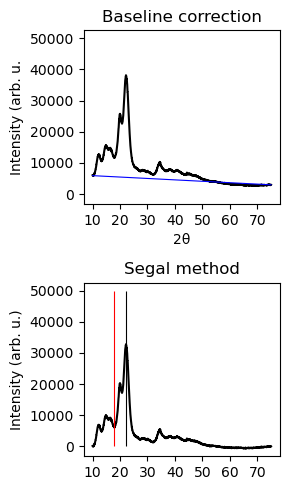

In [15]:
filepath = "CNC_Segal.txt"
segal(filepath)
plt.tight_layout()
plt.savefig('CNC_Segal.svg', bbox_inches = 'tight')

I_amorphous = 8357.146139971806, at x = 17.9255
I_crystalline = 18622.295228597635, at x = 22.2485
CI = 55.1228995277767


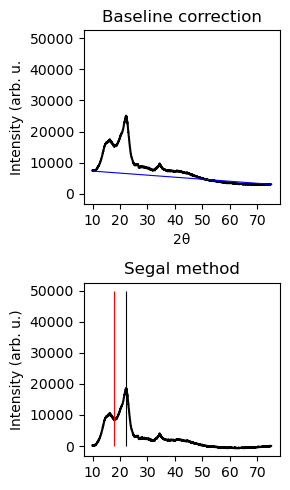

In [16]:
filepath = "CNF_Segal.txt"
segal(filepath)
plt.tight_layout()
plt.savefig('CNF_Segal.svg', bbox_inches = 'tight')